# PRÁTICA 3 — Word2Vec com skip-gram

**Grupo 6** · STIL 2017 · corpus herdado da PRÁTICA 1

`corpus → frases → skip-gram → vetores → similaridade → soma e subtração de vetores`

## Atividades

1. Vetores gerados para as palavras: **a)** modelos · **b)** linguagem · **c)** substantivo de maior frequência do corpus · **d)** verbo de maior frequência do corpus
2. Termos mais similares a essas mesmas quatro palavras
3. Soma e subtração de vetores com o Word2Vec pré-treinado e com o Word2Vec treinado nos artigos

A lógica fica em `ml/`; cada célula mostra um passo e o resultado dele.

## 0. Setup

- **Local:** `uv sync` dentro de `pratica-3-word2vec/` cria o `.venv` com o kernel.
- **Colab:** a célula abaixo clona o repositório, entra na pasta e instala o `gensim`.
- O Word2Vec pré-treinado (~380 MB) é baixado do Hugging Face na seção 6 e fica no cache, fora do repositório.

In [1]:
import os
import subprocess
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

IN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/joaoleahy/topicos-banco-de-dados-ii.git"
PASTA = "pratica-3-word2vec"
PKGS = ["gensim>=4.4", "huggingface-hub", "safetensors", "matplotlib"]


def ensure_project() -> Path:
    if Path("ml/skipgram.py").exists():
        return Path.cwd().resolve()
    if Path(f"{PASTA}/ml/skipgram.py").exists():
        os.chdir(PASTA)
        return Path.cwd().resolve()
    if IN_COLAB:
        dest = Path("/content/topicos-banco-de-dados-ii")
        if not dest.exists():
            subprocess.check_call(["git", "clone", "--depth", "1", REPO, str(dest)])
        os.chdir(dest / PASTA)
        return Path.cwd().resolve()
    raise FileNotFoundError(f"pasta ml/ não encontrada — rode o notebook de dentro de {PASTA}")


ROOT = ensure_project()
sys.path.insert(0, str(ROOT))

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PKGS])

print("projeto:", ROOT)
print("colab:", IN_COLAB)

projeto: /Users/antoniel/d/ufba/bd-2-llms/topicos-banco-de-dados-ii/pratica-3-word2vec
colab: False


## 1. Corpus — só os artigos em português

O snapshot `corpus/stil2017.jsonl` traz da PRÁTICA 1 o texto com pontuação (`artigo_tokenizado_pontuado`) e a classe gramatical de cada palavra (`pos_tagger`).

Usamos só os artigos em **português**: as palavras pedidas e o modelo pré-treinado são em português, e misturar idiomas espalharia os contextos de cada palavra.

In [2]:
from ml import herdar

herdar.run()

todos = herdar.carregar()
artigos = herdar.carregar("pt")

print("artigos:", len(todos), dict(Counter(a["idioma"] for a in todos)))
print("usando :", len(artigos), "(pt)")
print("\nexemplo:", artigos[0]["titulo"])
print(artigos[0]["artigo_tokenizado_pontuado"][:30])

artigos: 31 {'pt': 22, 'en': 9}
usando : 22 (pt)

exemplo: Uma Ferramenta para Identificar Desvios de Linguagem na Língua Portuguesa
['Os', 'desvios', 'de', 'linguagem', 'são', 'palavras', 'ou', 'construções', 'que', 'ferem', 'as', 'normas', 'gramaticais', 'e', 'costumam', 'ocorrer', 'por', 'descuido', 'ou', 'desconhecimento', 'das', 'regras', 'da', 'língua', '.', 'De', 'acordo', 'com', ',', 'o']


## 2. Frases — a entrada do Word2Vec

O skip-gram aprende olhando os vizinhos de cada palavra dentro de uma janela. A janela não deve atravessar o fim de uma frase, então o Word2Vec recebe **uma lista de frases**, e cada frase é uma lista de palavras.

`ml/frases.py`:
1. corta o artigo nos tokens de fim de frase (`.`, `!`, `?`, `;`);
2. fica só com as palavras, em minúsculas — pontuação e números saem;
3. descarta frases com menos de 2 palavras.

In [3]:
from ml import frases

tokens = artigos[0]["artigo_tokenizado_pontuado"]
cortado = frases.dividir_em_frases(tokens)

print("1. cortado em frases :", len(cortado), "frases")
print("   ", cortado[1])
print("2. só palavras       :", frases.so_palavras(cortado[1]))

1. cortado em frases : 73 frases
    ['De', 'acordo', 'com', ',', 'o', 'público-alvo', 'dos', 'revisores', 'gramaticais', 'tem', 'se', 'revelado', 'insatisfeito', 'com', 'a', 'restrição', 'de', 'intervenção', 'aos', 'problemas', 'ortográfico-sintáticos', ',', 'exigindo', 'a', 'consideração', 'de', 'problemas', 'relacionados', 'ao', 'estilo', ',', 'muito', 'mais', 'vinculados', 'à', 'eficácia', 'comunicativa', 'do', 'que', 'a', 'simples', 'adequação', 'à', 'norma', 'gramatical']
2. só palavras       : ['de', 'acordo', 'com', 'o', 'público-alvo', 'dos', 'revisores', 'gramaticais', 'tem', 'se', 'revelado', 'insatisfeito', 'com', 'a', 'restrição', 'de', 'intervenção', 'aos', 'problemas', 'ortográfico-sintáticos', 'exigindo', 'a', 'consideração', 'de', 'problemas', 'relacionados', 'ao', 'estilo', 'muito', 'mais', 'vinculados', 'à', 'eficácia', 'comunicativa', 'do', 'que', 'a', 'simples', 'adequação', 'à', 'norma', 'gramatical']


In [4]:
corpus = frases.preparar(artigos)
freq = Counter(palavra for frase in corpus for palavra in frase)

print(f"frases: {len(corpus):,} | palavras: {freq.total():,} | vocabulário: {len(freq):,}")
print("primeira frase:", corpus[0])

frases: 2,178 | palavras: 51,489 | vocabulário: 7,419
primeira frase: ['os', 'desvios', 'de', 'linguagem', 'são', 'palavras', 'ou', 'construções', 'que', 'ferem', 'as', 'normas', 'gramaticais', 'e', 'costumam', 'ocorrer', 'por', 'descuido', 'ou', 'desconhecimento', 'das', 'regras', 'da', 'língua']


## 3. Palavras-alvo — substantivo e verbo mais frequentes

A classe gramatical vem do `pos_tagger` da PRÁTICA 1 (spaCy). Contamos pela **forma** da palavra, porque é a forma que ganha vetor no Word2Vec (`construção` e `construções` têm vetores diferentes).

As estatísticas da PRÁTICA 1 usam os 31 artigos e por isso apontam `corpus` e `used` (dos artigos em inglês). Aqui o corpus é só o português.

In [5]:
from ml import frequencia

substantivos = frequencia.por_classe(artigos, "NOUN")
verbos = frequencia.por_classe(artigos, "VERB")

print("substantivos:", substantivos.most_common(5))
print("verbos      :", verbos.most_common(5))

substantivos: [('palavras', 156), ('dados', 154), ('base', 153), ('termos', 139), ('construções', 124)]
verbos      : [('pode', 79), ('podem', 62), ('partir', 52), ('apresenta', 49), ('tem', 40)]


In [6]:
SUBSTANTIVO = frequencia.mais_frequente(artigos, "NOUN")
VERBO = frequencia.mais_frequente(artigos, "VERB")
ALVOS = ["modelos", "linguagem", SUBSTANTIVO, VERBO]

for palavra in ALVOS:
    print(f"{palavra:<10} aparece {freq[palavra]:>4} vezes no corpus")

modelos    aparece   14 vezes no corpus
linguagem  aparece   49 vezes no corpus
palavras   aparece  161 vezes no corpus
pode       aparece   79 vezes no corpus


## 4. Treinar o Word2Vec com skip-gram

`ml/skipgram.py` chama o `gensim.models.Word2Vec` com `sg=1` (skip-gram).

| Hiperparâmetro | Valor | O que controla |
|---|---|---|
| `dimensoes` | 100 | tamanho de cada vetor (o mesmo do pré-treinado) |
| `janela` | 5 | quantos vizinhos de cada lado a palavra tenta prever |
| `frequencia_minima` | 3 | palavras mais raras ficam sem vetor |
| `epocas` | 50 | quantas vezes o treino passa pelo corpus |
| `seed` | 42 | com `workers=1` e um hash fixo, o resultado se repete |

In [7]:
from ml import skipgram

HIPERPARAMETROS = dict(dimensoes=100, janela=5, frequencia_minima=3, epocas=50)

modelo = skipgram.treinar(corpus, **HIPERPARAMETROS)
w2v = modelo.wv

print(f"vocabulário com vetor: {len(w2v):,} de {len(freq):,} palavras (as outras aparecem menos de 3 vezes)")
print(f"matriz de vetores: {w2v.vectors.shape}")
print("alvos no vocabulário:", {p: p in w2v for p in ALVOS})

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


vocabulário com vetor: 2,404 de 7,419 palavras (as outras aparecem menos de 3 vezes)
matriz de vetores: (2404, 100)
alvos no vocabulário: {'modelos': True, 'linguagem': True, 'palavras': True, 'pode': True}


> Se aparecer `Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'`: é um aviso interno do gensim 4.4. Ele não interrompe o treino, e os vetores saem idênticos em execuções repetidas.

### Quantas épocas?

O corpus tem ~51 mil palavras, pouco para o Word2Vec. Com poucas épocas, os vetores quase não saem do sorteio inicial, e os vizinhos são as palavras mais frequentes (`das`, `as`, `entre`). Com mais épocas, os vizinhos passam a refletir os contextos dos artigos.

In [8]:
from ml import vetores

por_epocas = {f"{e} épocas": skipgram.treinar(corpus, **{**HIPERPARAMETROS, "epocas": e}).wv for e in (5, 50, 100)}
pd.concat({palavra: vetores.tabela_similares(por_epocas, palavra, k=6) for palavra in ["linguagem", SUBSTANTIVO]}, axis=1)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


linguagem                                            \
               5 épocas            50 épocas           100 épocas   
0       tradução (1.00)     dinamismo (0.61)        modelo (0.53)   
1        máquina (1.00)        modelo (0.58)        vícios (0.53)   
2     quantidade (1.00)        vícios (0.56)     dinamismo (0.52)   
3        baseada (1.00)      n-gramas (0.53)  independente (0.50)   
4  representação (1.00)      informal (0.52)      contínua (0.46)   
5          maior (1.00)  independente (0.52)     constroem (0.46)   

             palavras                                              
             5 épocas             50 épocas            100 épocas  
0    sentenças (0.99)          blogs (0.49)      exagerada (0.46)  
1     relações (0.99)      exagerada (0.49)     barbarismo (0.45)  
2          das (0.99)     barbarismo (0.47)          blogs (0.45)  
3        entre (0.99)          longa (0.46)          longa (0.45)  
4   semânticas (0.99)  similaridades (0.46)  similaridades (0.45)  
5  construções (0.98)        ngramas (0.45)      oralidade (0.44)

## 5. Atividade 1 — vetores gerados

Cada palavra virou um vetor de 100 números. Isoladamente os números não têm significado; o que importa é a posição de um vetor em relação aos outros.

In [9]:
for palavra in ALVOS:
    v = w2v[palavra]
    print(f"{palavra} — {len(v)} dimensões, norma {np.linalg.norm(v):.2f}")
    print(np.array2string(v, precision=3, suppress_small=True, max_line_width=110), "\n")

modelos — 100 dimensões, norma 4.08
[ 0.115  0.118  0.239 -0.17   0.314  0.122 -0.027  0.18  -0.138  0.247 -0.162  0.034 -0.548  0.579  0.244
 -0.056  0.014 -0.898  0.227 -0.401  0.005 -0.235 -0.228  0.673  0.249 -0.124 -0.002 -0.084 -0.277  1.346
 -0.294 -0.658 -0.491 -0.36  -0.097  0.047  0.433 -0.976 -0.179  0.039  0.065 -0.036  0.47   0.053  0.346
  0.029  0.558  0.37   0.028 -0.293  0.243 -0.115  0.041 -0.621 -0.071 -0.396  0.193 -0.081 -0.037  0.81
 -0.52  -0.025  0.228 -0.841 -0.255  0.285  0.329 -0.75   0.666 -0.938 -0.196  0.275  0.074 -0.257 -0.056
 -0.312 -0.588 -0.252 -0.713  0.402 -0.571 -0.497 -0.268  0.294 -0.873  0.377  0.681 -0.434  0.123 -0.202
 -0.724  0.006 -0.049  0.138  0.133 -0.011  0.349  0.029 -0.041  0.444] 

linguagem — 100 dimensões, norma 4.75
[ 0.161  0.446 -0.139  0.53  -0.209 -0.084 -0.373  0.011  0.383  0.522 -0.496 -0.094 -0.321  0.258 -0.165
 -0.052  0.449 -0.687 -0.116  0.538 -0.788  0.263  0.031 -0.312  0.849 -0.512 -0.345  0.23  -0.44   0.173
 -0.2

In [10]:
pd.DataFrame({palavra: w2v[palavra] for palavra in ALVOS}).T.round(3)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
modelos,0.115,0.118,0.239,-0.170,0.314,0.122,-0.027,0.180,-0.138,0.247,...,-0.724,0.006,-0.049,0.138,0.133,-0.011,0.349,0.029,-0.041,0.444
linguagem,0.161,0.446,-0.139,0.530,-0.209,-0.084,-0.373,0.011,0.383,0.522,...,-0.157,0.713,-0.515,-0.778,-0.296,-0.012,-0.671,0.848,0.088,-0.138
palavras,0.499,0.458,0.349,0.708,-0.137,-0.289,-0.244,-0.103,-0.205,0.223,...,-0.422,0.786,0.386,0.049,0.366,-0.539,0.097,0.118,-0.890,-0.712
pode,0.029,1.121,-0.408,-0.644,-0.196,-0.849,-0.142,-0.117,0.405,-0.385,...,0.898,-0.009,0.252,0.100,0.075,0.179,-0.642,-0.203,0.208,0.302


## 6. Atividade 2 — termos mais similares

**Similaridade de cosseno** compara a direção de dois vetores: 1 = mesma direção, 0 = sem relação. Palavras usadas em contextos parecidos terminam com vetores próximos.

Primeiro, a similaridade entre as próprias palavras-alvo:

In [11]:
pd.DataFrame([[w2v.similarity(a, b) for b in ALVOS] for a in ALVOS], index=ALVOS, columns=ALVOS).round(2)

,modelos,linguagem,palavras,pode
modelos,1.00,0.26,0.05,0.13
linguagem,0.26,1.00,0.15,0.18
palavras,0.05,0.15,1.00,0.04
pode,0.13,0.18,0.04,1.00


A mesma matriz como **heatmap**: a cor no lugar do número (mais claro = mais similar). A escala ignora a diagonal, que é sempre 1.

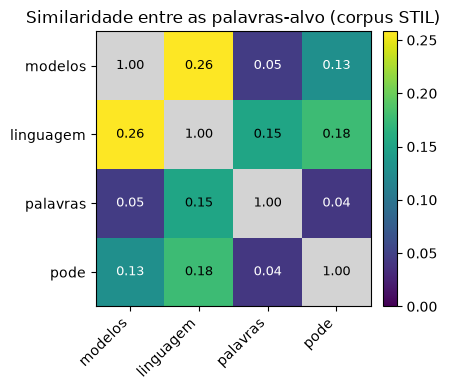

In [12]:
from ml import graficos

graficos.heatmap(w2v, ALVOS, "Similaridade entre as palavras-alvo (corpus STIL)");

### Os vetores num plano 2D

Cada vetor tem 100 dimensões. O **PCA** acha as duas direções em que os vetores mais variam e projeta cada palavra nelas: palavras próximas no plano tendem a ser próximas no modelo.

Só quatro pontos dizem pouco, então cada palavra-alvo entra com os seus 8 vizinhos mais similares, na mesma cor. A projeção perde informação: o título diz quanto da variância o plano guarda.

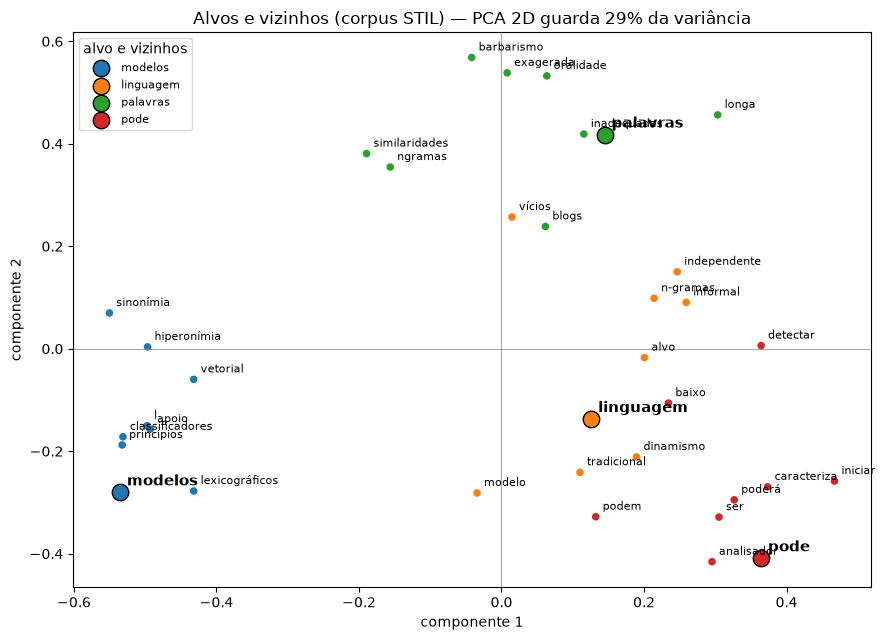

In [13]:
graficos.plano_2d(w2v, ALVOS, k=8, titulo="Alvos e vizinhos (corpus STIL)");

### a) modelos

In [14]:
vetores.tabela_similares({"corpus STIL": w2v}, "modelos")

,corpus STIL
0,classificadores (0.63)
1,vetorial (0.61)
2,lexicográficos (0.56)
3,l (0.56)
4,apoio (0.55)
5,princípios (0.53)
6,sinonímia (0.53)
7,hiperonímia (0.51)
8,destacados (0.50)
9,tep (0.50)


### b) linguagem

In [15]:
vetores.tabela_similares({"corpus STIL": w2v}, "linguagem")

,corpus STIL
0,dinamismo (0.61)
1,modelo (0.58)
2,vícios (0.56)
3,n-gramas (0.53)
4,informal (0.52)
5,independente (0.52)
6,tradicional (0.50)
7,alvo (0.50)
8,detecção (0.49)
9,xml (0.49)


### c) substantivo de maior frequência

In [16]:
vetores.tabela_similares({"corpus STIL": w2v}, SUBSTANTIVO)

,corpus STIL
0,blogs (0.49)
1,exagerada (0.49)
2,barbarismo (0.47)
3,longa (0.46)
4,similaridades (0.46)
5,ngramas (0.45)
6,oralidade (0.44)
7,inadequadas (0.44)
8,guias (0.43)
9,abrange (0.43)


### d) verbo de maior frequência

In [17]:
vetores.tabela_similares({"corpus STIL": w2v}, VERBO)

,corpus STIL
0,caracteriza (0.46)
1,baixo (0.46)
2,poderá (0.44)
3,ser (0.44)
4,detectar (0.44)
5,iniciar (0.43)
6,podem (0.42)
7,analisador (0.42)
8,poderia (0.41)
9,ocorrer (0.41)


## 7. Word2Vec pré-treinado — NILC

`nilc-nlp/word2vec-skip-gram-100d`: também skip-gram com 100 dimensões, mas treinado em **~1,39 bilhão de tokens** de português (Wikipedia, notícias, legendas, literatura).

É o modelo do artigo *Portuguese Word Embeddings: Evaluating on Word Analogies and Natural Language Tasks* (Hartmann et al.), publicado no próprio STIL 2017 — está no nosso corpus como `article_15` (em inglês, por isso fora do treino).

`ml/pretreinado.py` baixa `vocab.txt` + `embeddings.safetensors` e monta um `KeyedVectors` do gensim, o mesmo tipo do `w2v`.

In [18]:
from ml import pretreinado

nilc = pretreinado.carregar()

print(f"NILC : {len(nilc):>9,} palavras x {nilc.vector_size} dimensões")
print(f"nosso: {len(w2v):>9,} palavras x {w2v.vector_size} dimensões")

MODELOS = {"corpus STIL": w2v, "NILC pré-treinado": nilc}

NILC :   929,606 palavras x 100 dimensões
nosso:     2,404 palavras x 100 dimensões


### Atividade 2 nos dois modelos

O nosso modelo aprende os contextos dos artigos de PLN; o NILC, os contextos do português geral.

In [19]:
from IPython.display import display

for palavra in ALVOS:
    print(palavra)
    display(vetores.tabela_similares(MODELOS, palavra, k=8))

modelos


,corpus STIL,NILC pré-treinado
0,classificadores (0.63),protótipos (0.82)
1,vetorial (0.61),chipsets (0.79)
2,lexicográficos (0.56),itens (0.79)
3,l (0.56),processadores (0.79)
4,apoio (0.55),layouts (0.79)
5,princípios (0.53),designs (0.78)
6,sinonímia (0.53),microprocessadores (0.77)
7,hiperonímia (0.51),emuladores (0.77)


linguagem


,corpus STIL,NILC pré-treinado
0,dinamismo (0.61),sintaxe (0.86)
1,modelo (0.58),metalinguagem (0.84)
2,vícios (0.56),semântica (0.81)
3,n-gramas (0.53),imagética (0.80)
4,informal (0.52),ontologia (0.79)
5,independente (0.52),gramática (0.79)
6,tradicional (0.50),narrativa (0.78)
7,alvo (0.50),lógica (0.78)


palavras


,corpus STIL,NILC pré-treinado
0,blogs (0.49),frases (0.84)
1,exagerada (0.49),expressões (0.81)
2,barbarismo (0.47),afirmações (0.79)
3,longa (0.46),leituras (0.78)
4,similaridades (0.46),verdades (0.76)
5,ngramas (0.45),falas (0.76)
6,oralidade (0.44),citações (0.76)
7,inadequadas (0.44),asserções (0.76)


pode


,corpus STIL,NILC pré-treinado
0,caracteriza (0.46),deve (0.93)
1,baixo (0.46),poderia (0.92)
2,poderá (0.44),poderá (0.91)
3,ser (0.44),costuma (0.87)
4,detectar (0.44),possa (0.87)
5,iniciar (0.43),podia (0.85)
6,podem (0.42),deva (0.85)
7,analisador (0.42),deveria (0.84)


## 8. Atividade 3 — soma e subtração de vetores

`verbos − verbo + substantivo`: tira de `verbos` o que é "verbo" e soma o que é "substantivo". Se o modelo aprendeu a relação singular → plural, o vetor resultado fica perto de `substantivos`.

Passo a passo, no NILC, com os vetores normalizados (comprimento 1):

In [20]:
CONTA = "verbos - verbo + substantivo"

v_verbos, v_verbo, v_substantivo = (nilc.get_vector(p, norm=True) for p in ["verbos", "verbo", "substantivo"])
resultado = v_verbos - v_verbo + v_substantivo

print("vetor resultado (10 primeiras dimensões):", resultado[:10].round(3))
print("mesmo vetor que vetores.calcular:", np.allclose(resultado, vetores.calcular(nilc, CONTA)))

vetor resultado (10 primeiras dimensões): [-0.169 -0.319  0.003 -0.012  0.043 -0.071 -0.171  0.094 -0.162 -0.017]
mesmo vetor que vetores.calcular: True


O vetor resultado não é de nenhuma palavra. Procuramos as palavras mais próximas dele — mas as próprias palavras da conta costumam estar entre elas:

In [21]:
nilc.similar_by_vector(resultado, topn=5)

[('verbos', 0.8361641764640808),
 ('substantivos', 0.7960967421531677),
 ('sufixos', 0.7535354495048523),
 ('morfemas', 0.7418528199195862),
 ('pronomes', 0.7372284531593323)]

Por isso a resposta exclui as palavras da conta (é o que o `most_similar` do gensim faz):

In [22]:
vetores.resolver(nilc, CONTA)

[('substantivos', 0.796096682548523),
 ('sufixos', 0.7535354495048523),
 ('morfemas', 0.7418528199195862),
 ('pronomes', 0.7372284531593323),
 ('caracteres', 0.7172960042953491)]

### A conta como movimento no plano

`verbos − verbo` é uma **seta**: o caminho de `verbo` até `verbos` (singular → plural). Somar `substantivo` é fazer essa seta sair de `substantivo`. A ponta dela é o vetor resultado (★), e a resposta é a palavra mais próxima dele (em verde, na ordem de similaridade).

O resultado aparece com comprimento 1, como as palavras (o cosseno compara só a direção), então as duas setas saem parecidas, não idênticas. O plano é uma projeção: o título diz quanto da variância ele guarda. No NILC a seta leva a `substantivos`; no nosso modelo, treinado com pouco texto, ela não chega a um plural.

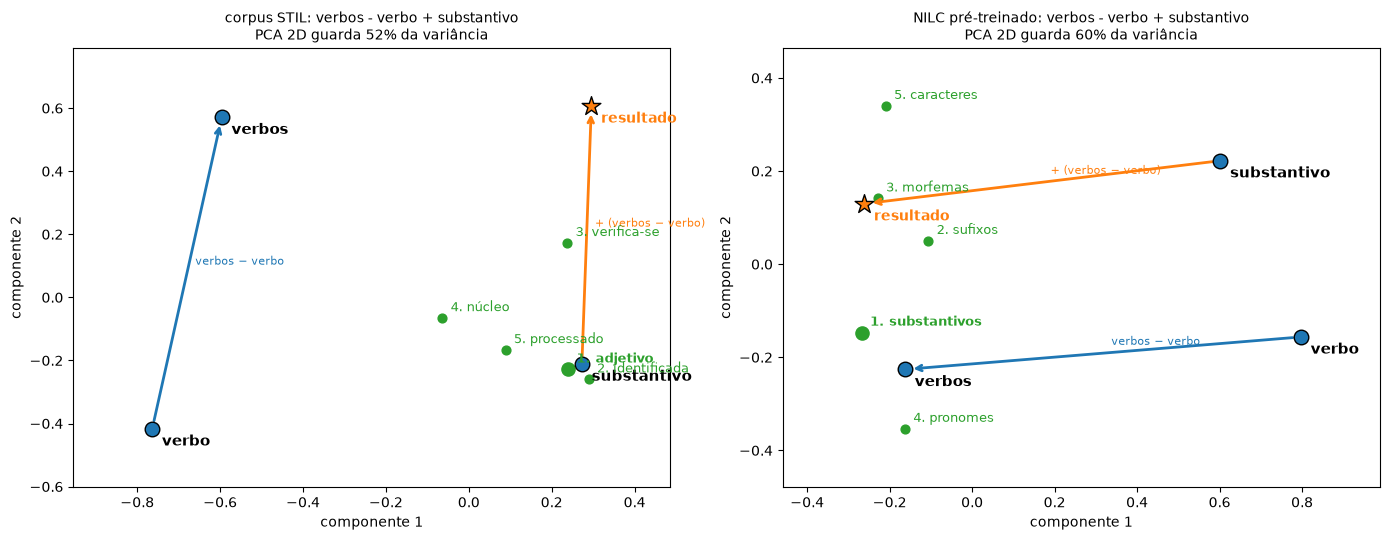

In [23]:
graficos.conta_2d_modelos(MODELOS, CONTA);

### Mesmas contas nos dois modelos

**Com termos dos artigos** — todas as palavras existem nos dois vocabulários:

In [24]:
CONTAS_DO_CORPUS = [
    "verbos - verbo + substantivo",
    "palavras - palavra + frase",
    "textos - texto + documento",
    "modelos - modelo + texto",
    "podem - pode + deve",
    "sentenças - sentença + palavra",
]
vetores.tabela_analogias(MODELOS, CONTAS_DO_CORPUS)

,corpus STIL,NILC pré-treinado
conta,,
verbos - verbo + substantivo,"adjetivo (0.51), identificada (0.47), verifica...","substantivos (0.80), sufixos (0.75), morfemas ..."
palavras - palavra + frase,"leva (0.40), comuns (0.39), negação (0.38)","frases (0.79), falas (0.69), afirmações (0.67)"
textos - texto + documento,"escritos (0.43), usuais (0.43), captura (0.43)","documentos (0.80), testemunhos (0.75), registo..."
modelos - modelo + texto,"consideradas (0.37), edição (0.36), excluídos ...","textos (0.81), cabeçalhos (0.71), apontamentos..."
podem - pode + deve,"consultas (0.46), indicar (0.45), outras (0.44)","devem (0.97), poderão (0.94), deverão (0.93)"
sentenças - sentença + palavra,"normalizadas (0.43), anotado (0.43), oov (0.40)","palavras (0.71), ab·bá (0.68), etimologias (0.68)"


**Com conhecimento geral** — o exemplo clássico e relações de país, capital e língua:

In [25]:
CONTAS_GERAIS = [
    "rei - homem + mulher",
    "brasília - brasil + portugal",
    "português - portugal + espanha",
    "melhor - bom + mau",
]
vetores.tabela_analogias(MODELOS, CONTAS_GERAIS)

,corpus STIL,NILC pré-treinado
conta,,
rei - homem + mulher,"fora do vocabulário: rei, mulher, homem","rainha-consorte (0.79), primogénita (0.77), im..."
brasília - brasil + portugal,fora do vocabulário: brasília,"lisboa (0.68), luanda (0.63), alvalade (0.60)"
português - portugal + espanha,fora do vocabulário: espanha,"espanhol (0.76), galego (0.70), castelhano (0.67)"
melhor - bom + mau,fora do vocabulário: mau,"pior (0.55), bloqueadora (0.47), episódica (0.46)"


## Conclusão

| | corpus STIL (nosso) | NILC pré-treinado |
|---|---|---|
| texto de treino | ~51 mil palavras, 22 artigos de PLN | ~1,39 bilhão de tokens de português geral |
| vocabulário com vetor | ~2,4 mil palavras | ~930 mil palavras |

**Atividade 1.** Cada palavra virou um vetor de 100 números. Entre as quatro palavras-alvo a similaridade é baixa: são palavras de contextos diferentes.

**Atividade 2.** No nosso modelo, os vizinhos refletem os **temas dos artigos**: `linguagem` fica perto de `vícios`, `informal` e `dinamismo` (o artigo sobre desvios de linguagem), e `modelos` perto de `classificadores` e `vetorial`. As similaridades são baixas (≈0,4–0,6) e há ruído (`l`, `baixo`), porque cada palavra aparece poucas vezes. No NILC, os vizinhos são da **mesma classe e do mesmo sentido** no português geral (`pode` → `deve`, `poderia`), e `modelos` puxa o sentido de produto (`protótipos`, `chipsets`), não o de PLN.

**Atividade 3.** O NILC acerta as contas com termos dos artigos (`verbos − verbo + substantivo` → `substantivos`, `podem − pode + deve` → `devem`) e as de conhecimento geral (`brasília − brasil + portugal` → `lisboa`, `melhor − bom + mau` → `pior`). O nosso modelo não acerta nenhuma: relações como singular → plural precisam de muitos exemplos para virar uma direção estável no espaço de vetores, e as palavras das contas gerais nem aparecem nos artigos.

O skip-gram é o mesmo nos dois modelos; a diferença vem do **tamanho e da variedade do texto de treino**.